# 22 - Scale confirmation at ~30M params on WikiText-103 (BPE)

The whole study so far is at ~3M params, char-level. The #1 reviewer objection is "does this hold
beyond toy scale?". Here we scale ~10x (n_embd=512, n_layer=8, n_head=8, ~30M params) on real
subword data (WikiText-103 BPE, 14.9M train tokens, vocab 8192, block 256) and re-test the two
load-bearing claims:

1. **combo beats baseline** (the modern recipe RoPE+SwiGLU+Pre-LN+RMSNorm genuinely helps), and
2. **combo_conv3 and combo_diff do NOT beat combo** (local conv and Differential Attention, which
   helped a *weak* baseline / win at large scale, do not improve the strong recipe at this scale).

**Power-cut resilient:** each config checkpoints (model+optimizer+iter) every 500 iters with an
atomic write, and resumes mid-training; finished configs are recorded in a CSV and skipped. A
power-cut therefore costs at most a couple of minutes, no matter how often it happens.


In [1]:
%matplotlib inline
import os, math, time, csv, json, gc
from contextlib import nullcontext
import numpy as np
import torch
import matplotlib.pyplot as plt
from model import Config, GPT, count_params

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

D = "../dataset"
train_data = torch.from_numpy(np.load(D + "/wt103_bpe_train.npy"))
val_data = torch.from_numpy(np.load(D + "/wt103_bpe_val.npy"))
vocab = json.load(open(D + "/wt103_bpe_meta.json"))["vocab"]
print(f"vocab={vocab}  train_tokens={len(train_data):,}  val_tokens={len(val_data):,}")

BLOCK, BATCH = 256, 16
CKPT_DIR = "../results/scale_ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

def get_batch(split, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK, (BATCH,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix])
    y = torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])
    return x.to(device), y.to(device)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()

def train_one(name, overrides, seed=0, max_iters=6000, eval_iters=200, lr=3e-4, warmup=200,
              min_lr=3e-5, ckpt_every=500):
    ckpt_path = f"{CKPT_DIR}/{name}.pt"
    torch.manual_seed(seed)
    cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=8, n_head=8, n_embd=512,
                 dropout=0.1, **overrides)
    model = GPT(cfg).to(device)
    pm = count_params(model) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.1)
    tg = torch.Generator().manual_seed(7777 + seed)
    start_it = 0
    if os.path.exists(ckpt_path):                       # resume mid-config after a power-cut
        ck = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        tg.set_state(ck["tg"]); start_it = ck["iter"]
        print(f"    [{name}] RESUMED from iter {start_it}/{max_iters}", flush=True)

    def get_lr(it):
        if it < warmup:
            return lr * (it + 1) / warmup
        r = (it - warmup) / max(1, max_iters - warmup)
        return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * r))

    def save_ckpt(it):                                  # atomic: write tmp then replace
        tmp = ckpt_path + ".tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "iter": it,
                    "tg": tg.get_state()}, tmp)
        os.replace(tmp, ckpt_path)

    @torch.no_grad()
    def ev():
        model.eval(); g = torch.Generator().manual_seed(4242); tot = 0.0
        for _ in range(eval_iters):
            x, y = get_batch("val", g)
            with autocast_ctx():
                _, loss = model(x, y)
            tot += loss.item()
        model.train(); return tot / eval_iters

    t0 = time.time()
    for it in range(start_it, max_iters):
        for grp in opt.param_groups:
            grp["lr"] = get_lr(it)
        x, y = get_batch("train", tg)
        with autocast_ctx():
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if it % 500 == 0 or it == max_iters - 1:
            print(f"    [{name}] iter {it:5d}/{max_iters}  train_loss {loss.item():.3f}  "
                  f"{(time.time()-t0)/60:.1f} min", flush=True)
        if (it + 1) % ckpt_every == 0:
            save_ckpt(it + 1)
    ppl = math.exp(ev())
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)                            # config done -> drop its checkpoint
    del model, opt
    gc.collect(); torch.cuda.empty_cache()
    return ppl, pm

print("ready  (BLOCK=%d BATCH=%d, checkpoint every 500 iters)" % (BLOCK, BATCH))


device: cuda NVIDIA GeForce RTX 3070
vocab=8192  train_tokens=14,923,628  val_tokens=281,169
ready  (BLOCK=256 BATCH=16, checkpoint every 500 iters)


In [2]:
COMBO = {"pos_encoding": "rope", "activation": "swiglu", "norm_placement": "pre", "norm_type": "rmsnorm"}
CONFIGS = {
    "baseline":    {},
    "combo":       COMBO,
    "combo_conv3": {**COMBO, "conv_kernel": 3},
    "combo_diff":  {**COMBO, "attention": "diff"},
}
MAX_ITERS = 6000

runs_csv = "../results/scale_confirm_runs.csv"

# RESUMABLE: load configs already completed, skip them, append new ones.
summary = {}
if os.path.exists(runs_csv):
    with open(runs_csv) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 3:
                summary[row[0]] = (float(row[2]), float(row[1]))
if not os.path.exists(runs_csv):
    with open(runs_csv, "w", newline="") as f:
        csv.writer(f).writerow(["config", "params_M", "val_ppl"])
if summary:
    print("RESUMING - configs already done:", list(summary), flush=True)

t0 = time.time()
for name, over in CONFIGS.items():
    if name in summary:
        print(f"=== {name} (skip, already done: ppl {summary[name][0]:.3f}) ===", flush=True)
        continue
    print(f"=== {name} ===", flush=True)
    p, pm = train_one(name, over, seed=0, max_iters=MAX_ITERS)
    summary[name] = (p, pm)
    with open(runs_csv, "a", newline="") as f:
        csv.writer(f).writerow([name, f"{pm:.3f}", f"{p:.4f}"])
    print(f"{name:12s} DONE  ppl {p:.3f}  ({pm:.1f}M)  | total {(time.time()-t0)/60:.1f} min\n", flush=True)
print(f"ALL DONE in {(time.time()-t0)/60:.1f} min")


=== baseline ===


    [baseline] iter     0/6000  train_loss 9.087  0.0 min


    [baseline] iter   500/6000  train_loss 5.787  0.6 min


    [baseline] iter  1000/6000  train_loss 5.171  1.2 min


    [baseline] iter  1500/6000  train_loss 4.913  1.9 min


    [baseline] iter  2000/6000  train_loss 4.597  2.5 min


... (51 outputs left out)

    [combo_diff] iter  5500/6000  train_loss 4.099  11.7 min


    [combo_diff] iter  5999/6000  train_loss 4.088  12.8 min


combo_diff   DONE  ppl 58.548  (29.4M)  | total 40.3 min



ALL DONE in 40.3 min


config         params       ppl   vs base  vs combo
combo_conv3     29.4M    49.722   -19.53%    -9.82%
combo           29.4M    55.136   -10.76%    +0.00%
combo_diff      29.4M    58.548    -5.24%    +6.19%
baseline        29.4M    61.787    +0.00%   +12.06%

--- VERDICT (scale confirmation) ---
1) combo vs baseline: -10.76%  -> CONFIRMED combo helps
2) combo_conv3 vs combo: -9.82%  -> conv HELPS at scale (new!)
3) combo_diff vs combo:  +6.19%  -> CONFIRMED diff does NOT help the strong recipe


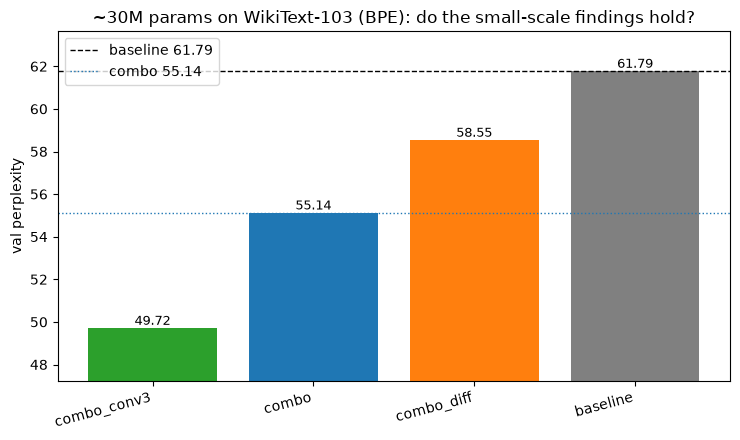

In [3]:
bppl = summary["baseline"][0]; cppl = summary["combo"][0]
print(f"{'config':12s} {'params':>8s} {'ppl':>9s} {'vs base':>9s} {'vs combo':>9s}")
for name, (p, pm) in sorted(summary.items(), key=lambda kv: kv[1][0]):
    print(f"{name:12s} {pm:7.1f}M {p:9.3f} {100*(p-bppl)/bppl:+8.2f}% {100*(p-cppl)/cppl:+8.2f}%")

combo_gain = 100 * (cppl - bppl) / bppl
conv_d = 100 * (summary["combo_conv3"][0] - cppl) / cppl
diff_d = 100 * (summary["combo_diff"][0] - cppl) / cppl
print(f"\n--- VERDICT (scale confirmation) ---")
print(f"1) combo vs baseline: {combo_gain:+.2f}%  -> {'CONFIRMED combo helps' if combo_gain < 0 else 'NOT confirmed'}")
print(f"2) combo_conv3 vs combo: {conv_d:+.2f}%  -> {'CONFIRMED conv does NOT help the strong recipe' if conv_d >= -1.0 else 'conv HELPS at scale (new!)'}")
print(f"3) combo_diff vs combo:  {diff_d:+.2f}%  -> {'CONFIRMED diff does NOT help the strong recipe' if diff_d >= -1.0 else 'diff HELPS at scale (new!)'}")

order = sorted(summary.items(), key=lambda kv: kv[1][0])
names = [n for n, _ in order]; ppls = [v[0] for _, v in order]
colors = ["gray" if n == "baseline" else "tab:blue" if n == "combo"
          else ("tab:green" if v[0] < cppl - 0.01 else "tab:orange") for n, v in order]
plt.figure(figsize=(7.5, 4.5))
plt.bar(names, ppls, color=colors)
plt.axhline(bppl, ls="--", c="black", lw=1, label=f"baseline {bppl:.2f}")
plt.axhline(cppl, ls=":", c="tab:blue", lw=1, label=f"combo {cppl:.2f}")
plt.ylabel("val perplexity"); plt.title("~30M params on WikiText-103 (BPE): do the small-scale findings hold?")
plt.xticks(rotation=15, ha="right"); plt.legend()
plt.ylim(min(ppls) * 0.95, max(ppls) * 1.03)
for i, p in enumerate(ppls):
    plt.text(i, p, f"{p:.2f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig("../results/scale_confirm.png", dpi=140); plt.show()


## Reading this

This is the credibility experiment for a Q1 submission. If (1) combo beats baseline AND (2) neither
conv nor diff beats the combo, the small-scale (3M, char) conclusions transfer to ~30M params on real
subword data - directly answering the "toy scale" objection. A green bar (conv/diff beating combo)
would instead be a genuine scale-dependent finding worth its own investigation.
